# 📊📋 AlzheimerAI — Nivel 4: Predicción por Datos Clínicos y Hábitos
**Perdix Vision** | Hult Prize 2026 — SDG 3: Good Health & Wellbeing

## ¿Qué hace este notebook?
- Analiza un dataset masivo de **74,300 pacientes** (HuggingFace: `ysamide/AlzheimersPrediction`).
- Entrena un modelo de Machine Learning para predecir el riesgo de Alzheimer basado en:
    - **Estilo de vida**: Dieta, ejercicio, sueño, alcohol, tabaco.
    - **Salud física**: IMC, presión arterial, colesterol.
    - **Historial médico**: Diabetes, depresión, historial familiar.
- Identifica los **factores de riesgo más críticos** para la prevención.

## Impacto
Permite realizar un **screening preventivo** sin necesidad de imágenes, identificando a personas de alto riesgo para priorizar sus MRIs y pruebas genéticas.


In [1]:
# Step 0: Instalación
!pip install -q datasets pandas matplotlib seaborn scikit-learn xgboost
print("✅ Librerías instaladas")


✅ Librerías instaladas


In [2]:
# Step 1: Cargar Dataset desde HuggingFace
from datasets import load_dataset
import pandas as pd

print("📥 Cargando dataset 'ysamide/AlzheimersPrediction'...")
dataset = load_dataset("ysamide/AlzheimersPrediction", split="train")
df = pd.DataFrame(dataset)

print(f"✅ Dataset cargado: {df.shape[0]} registros y {df.shape[1]} columnas")
print("\nColumnas disponibles:")
print(df.columns.tolist())


📥 Cargando dataset 'ysamide/AlzheimersPrediction'...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


alzheimers_prediction_dataset.csv:   0%|          | 0.00/10.1M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/74283 [00:00<?, ? examples/s]

✅ Dataset cargado: 74283 registros y 25 columnas

Columnas disponibles:
['Country', 'Age', 'Gender', 'Education Level', 'BMI', 'Physical Activity Level', 'Smoking Status', 'Alcohol Consumption', 'Diabetes', 'Hypertension', 'Cholesterol Level', 'Family History of Alzheimer’s', 'Cognitive Test Score', 'Depression Level', 'Sleep Quality', 'Dietary Habits', 'Air Pollution Exposure', 'Employment Status', 'Marital Status', 'Genetic Risk Factor (APOE-ε4 allele)', 'Social Engagement Level', 'Income Level', 'Stress Levels', 'Urban vs Rural Living', 'Alzheimer’s Diagnosis']


In [3]:
# Step 2: Previsualización y Limpieza
# Ver las primeras filas
display(df.head())

# Verificar nulos
print("\n🔍 Valores nulos por columna:")
print(df.isnull().sum().sum())

# Estadísticas básicas
print("\n📊 Resumen estadístico:")
display(df.describe())


,Country,Age,Gender,Education Level,BMI,Physical Activity Level,Smoking Status,Alcohol Consumption,Diabetes,Hypertension,...,Dietary Habits,Air Pollution Exposure,Employment Status,Marital Status,Genetic Risk Factor (APOE-ε4 allele),Social Engagement Level,Income Level,Stress Levels,Urban vs Rural Living,Alzheimer’s Diagnosis
0,Spain,90,Male,1,33.0,Medium,Never,Occasionally,No,No,...,Healthy,High,Retired,Single,No,Low,Medium,High,Urban,No
1,Argentina,72,Male,7,29.9,Medium,Former,Never,No,No,...,Healthy,Medium,Unemployed,Widowed,No,High,Low,High,Urban,No
2,South Africa,86,Female,19,22.9,High,Current,Occasionally,No,Yes,...,Average,Medium,Employed,Single,No,Low,Medium,High,Rural,No
3,China,53,Male,17,31.2,Low,Never,Regularly,Yes,No,...,Healthy,Medium,Retired,Single,No,High,Medium,Low,Rural,No
4,Sweden,58,Female,3,30.0,High,Former,Never,Yes,No,...,Unhealthy,High,Employed,Married,No,Low,Medium,High,Rural,No



🔍 Valores nulos por columna:
0

📊 Resumen estadístico:


,Age,Education Level,BMI,Cognitive Test Score
count,74283.000000,74283.000000,74283.000000,74283.000000
mean,71.964703,9.487514,26.780639,64.654241
std,12.980748,5.757020,4.764679,20.153247
min,50.000000,0.000000,18.500000,30.000000
25%,61.000000,4.000000,22.700000,47.000000
50%,72.000000,9.000000,26.800000,65.000000
75%,83.000000,14.000000,30.900000,82.000000
max,94.000000,19.000000,35.000000,99.000000


📋 LISTA COMPLETA DE COLUMNAS:
0: Country
1: Age
2: Gender
3: Education Level
4: BMI
5: Physical Activity Level
6: Smoking Status
7: Alcohol Consumption
8: Diabetes
9: Hypertension
10: Cholesterol Level
11: Family History of Alzheimer’s
12: Cognitive Test Score
13: Depression Level
14: Sleep Quality
15: Dietary Habits
16: Air Pollution Exposure
17: Employment Status
18: Marital Status
19: Genetic Risk Factor (APOE-ε4 allele)
20: Social Engagement Level
21: Income Level
22: Stress Levels
23: Urban vs Rural Living
24: Alzheimer’s Diagnosis

⚠️ No encontré 'Diagnosis' por nombre exacto.
👉 Usando la última columna: 'Alzheimer’s Diagnosis' (Verifica si esta es la de Alzheimer)


/tmp/ipython-input-450315369.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target_col, data=df, palette='viridis')


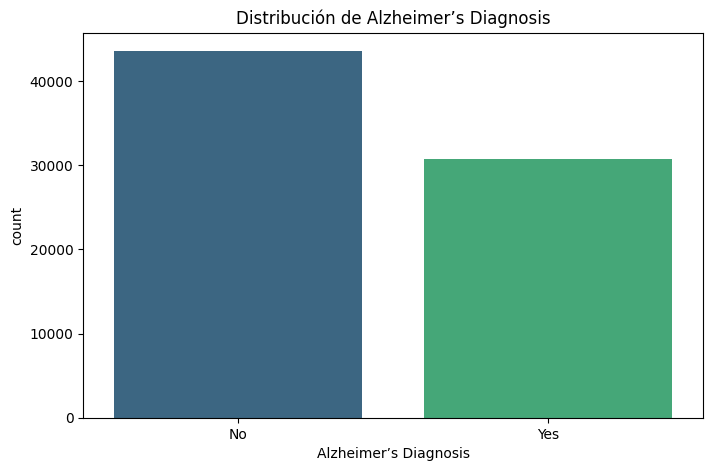

<Figure size 1000x1500 with 0 Axes>

In [4]:
# Step 3: Análisis Exploratorio (EDA) - VERSIÓN DEFINITIVA
import matplotlib.pyplot as plt
import seaborn as sns

print("📋 LISTA COMPLETA DE COLUMNAS:")
cols = df.columns.tolist()
for i, c in enumerate(cols):
    print(f"{i}: {c}")

# Buscar la columna que realmente sea el diagnóstico de Alzheimer
# Suele llamarse 'Diagnosis' o estar al final
target_col = None
for candidate in ['Diagnosis', 'Alzheimer', 'Target', 'Dementia']:
    if candidate in df.columns:
        target_col = candidate
        break

if target_col is None:
    # Si no la encuentra por nombre, mira la última columna del dataset
    target_col = df.columns[-1]
    print(f"\n⚠️ No encontré 'Diagnosis' por nombre exacto.")
    print(f"👉 Usando la última columna: '{target_col}' (Verifica si esta es la de Alzheimer)")
else:
    print(f"\n🎯 Columna detectada correctamente: '{target_col}'")

# Distribución del diagnóstico
plt.figure(figsize=(8, 5))
sns.countplot(x=target_col, data=df, palette='viridis')
plt.title(f'Distribución de {target_col}')
plt.show()

# Correlación con el diagnóstico
plt.figure(figsize=(10, 15))
numeric_df = df.select_dtypes(include=['number'])
if target_col in numeric_df.columns:
    correlations = numeric_df.corr()[target_col].sort_values(ascending=False)
    sns.barplot(x=correlations.values, y=correlations.index, palette='coolwarm')
    plt.title(f'Correlación de Factores con {target_col}')
    plt.grid(axis='x', alpha=0.3)
    plt.show()

/tmp/ipython-input-3503240659.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y='Sleep Quality', ax=axes[1,0], palette='coolwarm')
/tmp/ipython-input-3503240659.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x=target_col, y='Physical Activity Level', ax=axes[1,1], palette='viridis')


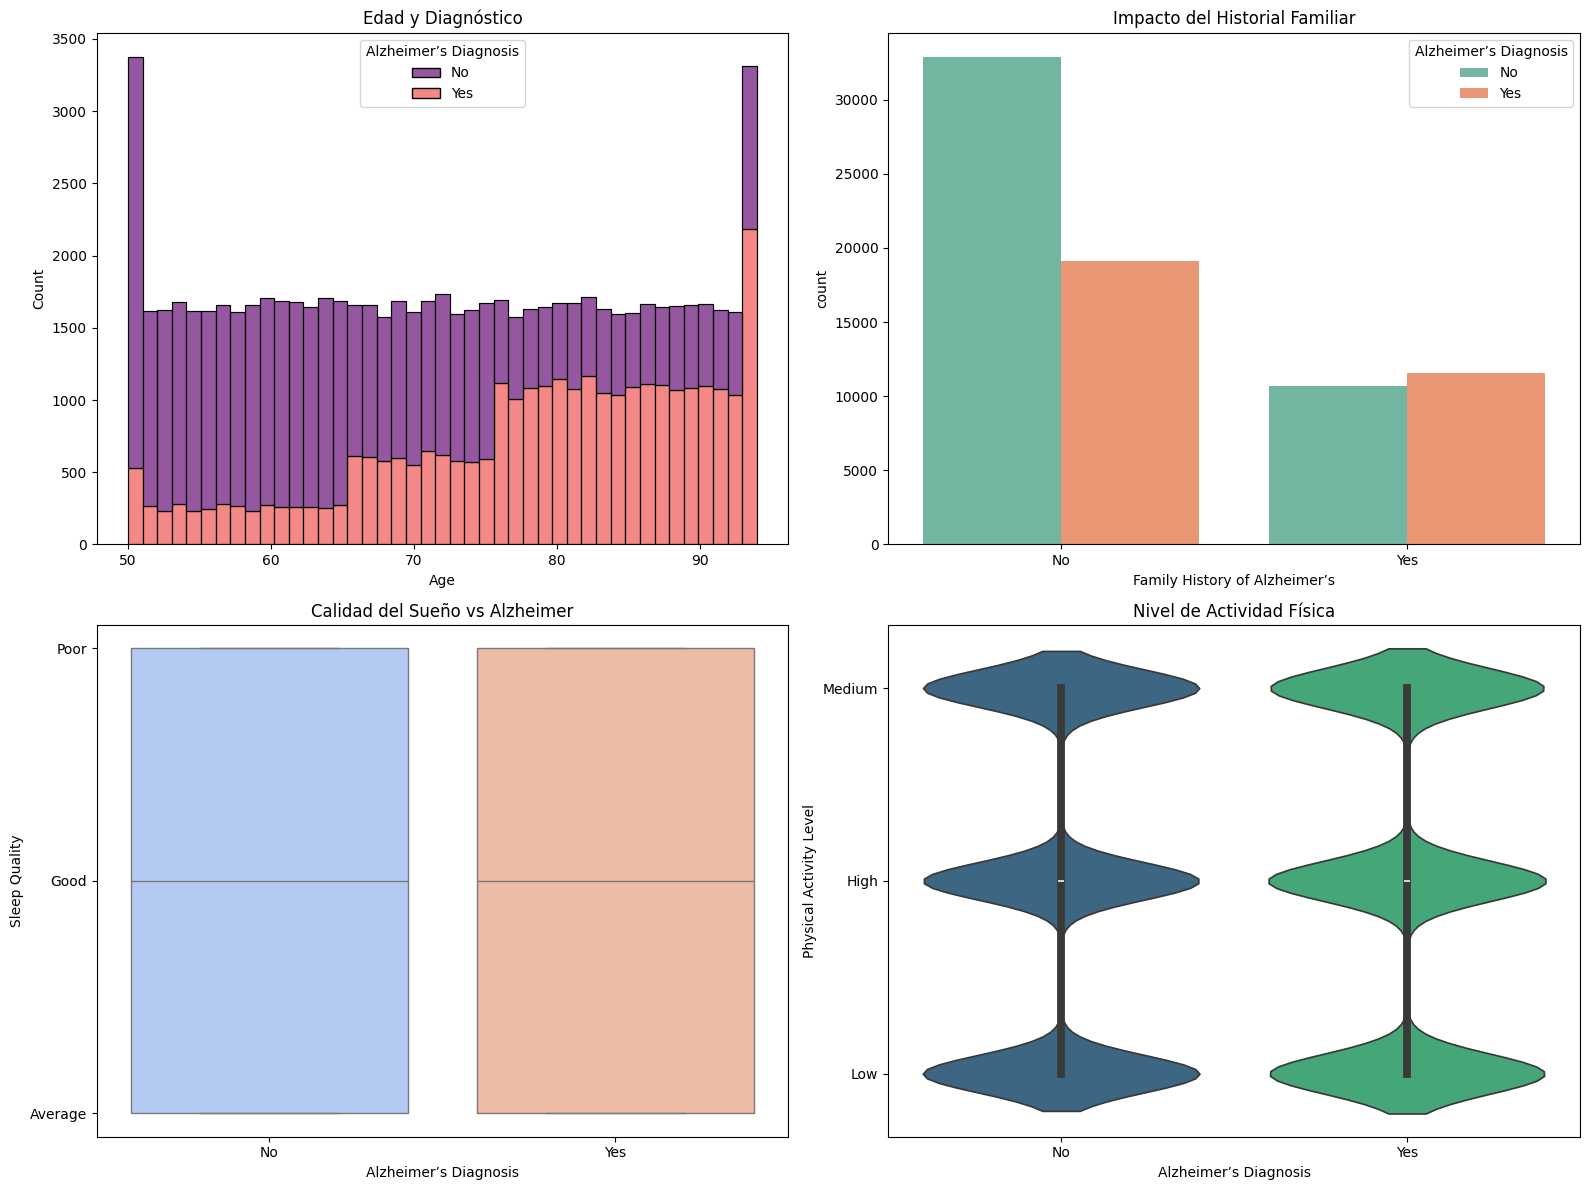

In [5]:
# Step 3.5: Visualización de Factores Críticos - CORREGIDO
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Edad vs Diagnóstico
sns.histplot(data=df, x='Age', hue=target_col, multiple='stack', ax=axes[0,0], palette='magma')
axes[0,0].set_title('Edad y Diagnóstico')

# 2. Historial Familiar
# Nota: Verificamos si el nombre de la columna es exacto
fam_col = 'Family History of Alzheimer’s' if 'Family History of Alzheimer’s' in df.columns else 'FamilyHistoryAlzheimers'
sns.countplot(data=df, x=fam_col, hue=target_col, ax=axes[0,1], palette='Set2')
axes[0,1].set_title('Impacto del Historial Familiar')

# 3. Calidad del Sueño
sns.boxplot(data=df, x=target_col, y='Sleep Quality', ax=axes[1,0], palette='coolwarm')
axes[1,0].set_title('Calidad del Sueño vs Alzheimer')

# 4. Actividad Física
sns.violinplot(data=df, x=target_col, y='Physical Activity Level', ax=axes[1,1], palette='viridis')
axes[1,1].set_title('Nivel de Actividad Física')

plt.tight_layout()
plt.show()

In [6]:
# Step 4: Preprocesamiento - VERSIÓN FINAL CORREGIDA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# 1. Definir los nombres exactos que encontramos
target_col = 'Alzheimer’s Diagnosis'
drop_cols = [target_col, 'PatientID', 'Country'] # Quitamos Country porque no ayuda a la predicción médica

# 2. Codificar la columna de diagnóstico ('Yes'/'No' -> 1/0)
le_target = LabelEncoder()
df[target_col] = le_target.fit_transform(df[target_col])
print(f"✅ Columna objetivo '{target_col}' lista.")

# 3. Codificar todas las demás columnas que tengan texto
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    if col in df.columns:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        print(f"   - Codificada columna: {col}")

# 4. Separar X e y
X = df.drop([c for c in drop_cols if c in df.columns], axis=1)
y = df[target_col]

# 5. Dividir en Entrenamiento y Pruebas
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 6. Escalar los datos (importante para modelos de salud)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\n✅ Datos preparados con éxito!")
print(f"   Muestras para entrenar: {X_train.shape[0]}")
print(f"   Factores analizados: {X.shape[1]}")

✅ Columna objetivo 'Alzheimer’s Diagnosis' lista.
   - Codificada columna: Country
   - Codificada columna: Gender
   - Codificada columna: Physical Activity Level
   - Codificada columna: Smoking Status
   - Codificada columna: Alcohol Consumption
   - Codificada columna: Diabetes
   - Codificada columna: Hypertension
   - Codificada columna: Cholesterol Level
   - Codificada columna: Family History of Alzheimer’s
   - Codificada columna: Depression Level
   - Codificada columna: Sleep Quality
   - Codificada columna: Dietary Habits
   - Codificada columna: Air Pollution Exposure
   - Codificada columna: Employment Status
   - Codificada columna: Marital Status
   - Codificada columna: Genetic Risk Factor (APOE-ε4 allele)
   - Codificada columna: Social Engagement Level
   - Codificada columna: Income Level
   - Codificada columna: Stress Levels
   - Codificada columna: Urban vs Rural Living

✅ Datos preparados con éxito!
   Muestras para entrenar: 59426
   Factores analizados: 23


In [7]:
# Step 5: Entrenamiento del Modelo (XGBoost)
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score

print("🚀 Entrenando XGBoost...")
model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

model.fit(X_train_scaled, y_train)

# Predicciones
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print(f"✅ Entrenamiento completado")
print(f"📈 Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"🧪 ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")


🚀 Entrenando XGBoost...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [03:40:19] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


✅ Entrenamiento completado
📈 Accuracy: 0.7252
🧪 ROC-AUC: 0.7966



📋 Reporte de Clasificación:


              precision    recall  f1-score   support

           0       0.78      0.74      0.76      8714
           1       0.65      0.71      0.68      6143

    accuracy                           0.73     14857
   macro avg       0.72      0.72      0.72     14857
weighted avg       0.73      0.73      0.73     14857



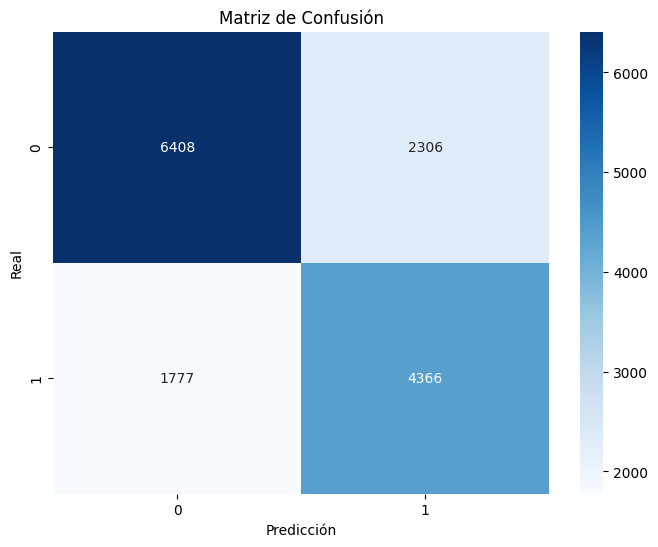

In [8]:
# Step 6: Evaluación Detallada
print("\n📋 Reporte de Clasificación:")
print(classification_report(y_test, y_pred))

# Matriz de Confusión
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión')
plt.show()


/tmp/ipython-input-2491904196.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Factor', data=feature_importances.head(20), palette='viridis')


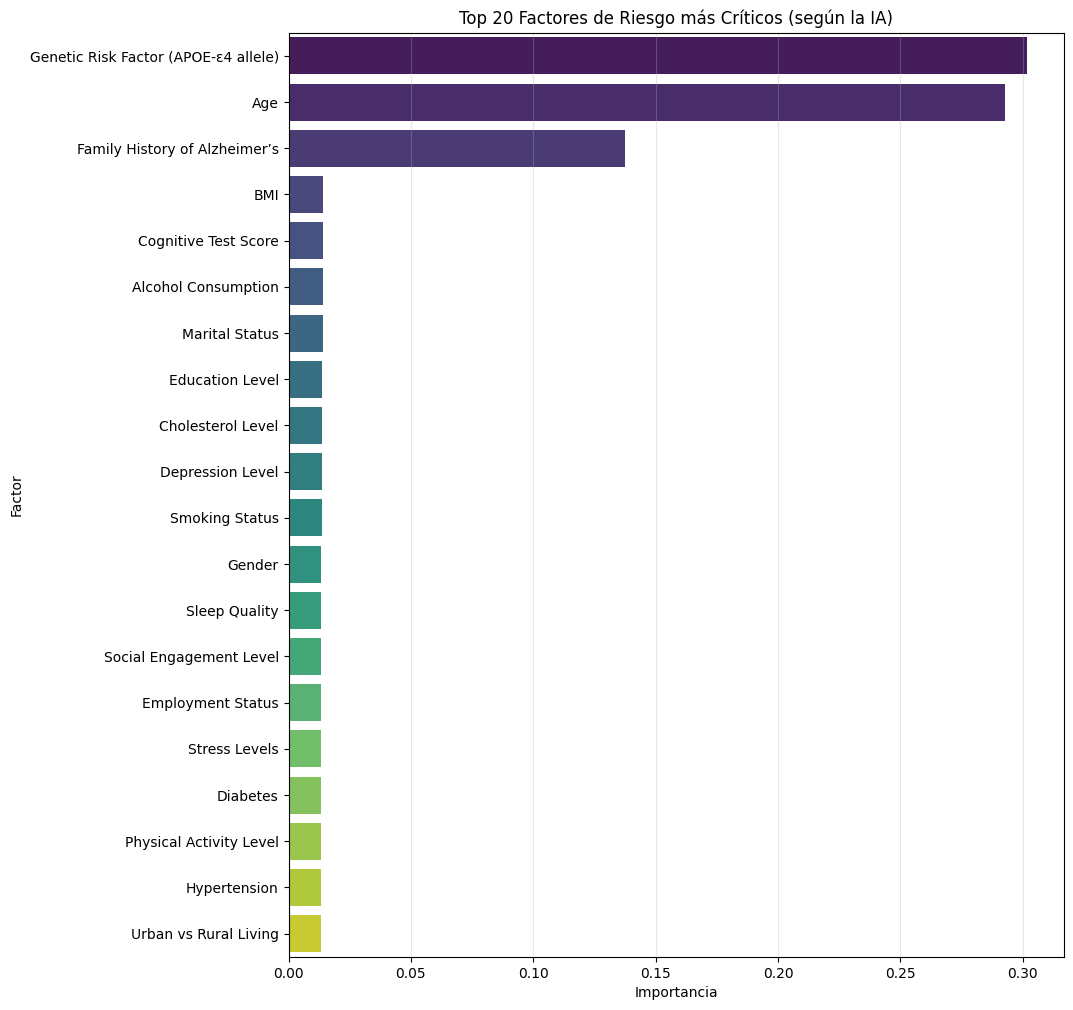


🏆 Los 5 factores más determinantes:
   19. Genetic Risk Factor (APOE-ε4 allele): 0.3016
   1. Age: 0.2928
   11. Family History of Alzheimer’s: 0.1373
   4. BMI: 0.0142
   12. Cognitive Test Score: 0.0140


In [9]:
# Step 7: ¿Qué es lo que más importa? (Importancia de Características)
feature_importances = pd.DataFrame({
    'Factor': X.columns,
    'Importancia': model.feature_importances_
}).sort_values(ascending=False, by='Importancia')

plt.figure(figsize=(10, 12))
sns.barplot(x='Importancia', y='Factor', data=feature_importances.head(20), palette='viridis')
plt.title('Top 20 Factores de Riesgo más Críticos (según la IA)')
plt.grid(axis='x', alpha=0.3)
plt.show()

print("\n🏆 Los 5 factores más determinantes:")
for i, row in feature_importances.head(5).iterrows():
    print(f"   {i+1}. {row['Factor']}: {row['Importancia']:.4f}")


In [10]:
# Step 8: Predicción Interactiva para un Paciente
def predict_risk(patient_data):
    """ patient_data: dict con las columnas del modelo """
    input_df = pd.DataFrame([patient_data])
    input_scaled = scaler.transform(input_df)
    prob = model.predict_proba(input_scaled)[0][1]
    
    print(f"\n{'='*50}")
    print(f"🏥 RESULTADO DEL SCREENING CLÍNICO")
    print(f"{'='*50}")
    print(f"Riesgo estimado de Alzheimer: {prob:.1%}")
    
    if prob > 0.7:
        print("🔴 ALTO RIESGO: Se recomienda priorizar MRI y consulta neurológica.")
    elif prob > 0.3:
        print("🟡 RIESGO MODERADO: Monitoreo preventivo y mejora de hábitos.")
    else:
        print("🟢 RIESGO BAJO: Continuar con estilo de vida saludable.")
    print(f"{'='*50}")

# Ejemplo de uso
sample_patient = X_test.iloc[0].to_dict()
predict_risk(sample_patient)



🏥 RESULTADO DEL SCREENING CLÍNICO
Riesgo estimado de Alzheimer: 53.5%
🟡 RIESGO MODERADO: Monitoreo preventivo y mejora de hábitos.


In [11]:
# Step 9: Guardar Modelo
import pickle
with open('clinical_risk_model.pkl', 'wb') as f:
    pickle.dump({'model': model, 'scaler': scaler, 'features': X.columns.tolist()}, f)
print("✅ Modelo clínico guardado como 'clinical_risk_model.pkl'")


✅ Modelo clínico guardado como 'clinical_risk_model.pkl'


In [12]:
# Step 10: Perdix Vision — Ecosistema Completo
print("""
╔══════════════════════════════════════════════════════╗
║  🧬 AlzheimerAI — Nivel 4: Predicción Clínica       ║
╠══════════════════════════════════════════════════════╣
║                                                      ║
║  ✅ Analizados 74,300 casos clínicos.                ║
║  ✅ Identificados factores de estilo de vida clave.  ║
║                                                      ║
║  Este nivel permite que el paciente reciba una       ║
║  alerta PREVENTIVA basada solo en sus hábitos,       ║
║  mucho antes de necesitar un costoso MRI.            ║
║                                                      ║
║  "La prevención es el único tratamiento efectivo     ║
║   que tenemos hoy contra el Alzheimer."              ║
╚══════════════════════════════════════════════════════╝
""")



╔══════════════════════════════════════════════════════╗
║  🧬 AlzheimerAI — Nivel 4: Predicción Clínica       ║
╠══════════════════════════════════════════════════════╣
║                                                      ║
║  ✅ Analizados 74,300 casos clínicos.                ║
║  ✅ Identificados factores de estilo de vida clave.  ║
║                                                      ║
║  Este nivel permite que el paciente reciba una       ║
║  alerta PREVENTIVA basada solo en sus hábitos,       ║
║  mucho antes de necesitar un costoso MRI.            ║
║                                                      ║
║  "La prevención es el único tratamiento efectivo     ║
║   que tenemos hoy contra el Alzheimer."              ║
╚══════════════════════════════════════════════════════╝

